In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare

In [3]:
STRATEGIES = {
    "BuyHold": {"minimum_profit": np.inf, "minimum_loss": 0.0},
    "Default": {},
    "Experimental1": {"cooldown_long": 180.0, "cooldown_short": 90.0},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_prices

,BTC,ETH,XRP,BNB,ADA,SOL,DOGE,DOT,LTC,LINK,...,XVG,BCN,NXT,PPC,NMC,DGB,SC,QTUM,ICX,LSK
Date,,,,,,,,,,,,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.058550,NaN,...,NaN,NaN,NaN,1.540270,1.264560,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.685230,NaN,...,NaN,NaN,NaN,1.685280,1.229760,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.327770,NaN,...,NaN,NaN,NaN,1.216330,1.104190,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.286440,NaN,...,NaN,NaN,NaN,1.641050,1.194410,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.245920,NaN,...,NaN,NaN,NaN,1.488790,1.110980,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,1.334452,740.823608,0.223782,106.422340,0.081809,1.149771,61.531612,12.320927,...,0.002583,0.000059,NaN,0.446449,1.317299,0.003360,0.000820,0.877745,0.009176,0.197685
2026-10-21,84011.968750,2470.766113,1.363619,745.868347,0.224979,106.793655,0.081867,1.141323,61.454342,12.484719,...,0.002605,0.000037,NaN,0.343409,1.176803,0.003399,0.000850,0.889200,0.008703,0.196787
2026-10-22,81311.890625,2386.189209,1.307656,730.476624,0.212025,103.542320,0.078676,1.111869,58.756485,11.943166,...,0.002455,0.000029,NaN,0.342047,1.535211,0.003527,0.000893,0.852186,0.009433,0.183983


# COMPARE

In [5]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=1000,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 3/3 [20:54<00:00, 418.28s/it]


In [6]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,MDD,Survival,RoAC,iteration
0,BuyHold,XMR,2069,0,2671,2069,2671,62,-6943,43.142857,65,1
1,BuyHold,SOL,2059,0,20527,2059,20527,92,-27045,70.571429,765,1
2,BuyHold,SRM,2059,0,642,2059,642,4,-845,98.800000,-53,1
3,BuyHold,ETH,2059,0,8501,2059,8501,82,-15303,188.500000,356,1
4,BuyHold,LTC,2069,0,25903,2069,25903,84,-133878,0.000000,907,1
...,...,...,...,...,...,...,...,...,...,...,...,...
28167,Experimental1,ZEC,3098,3065,2364,1601,5429,29,-2153,25.428571,3,1000
28168,Experimental1,SOL,2583,8703,748,717,9452,84,-2708,13.000000,201,1000
28169,Experimental1,XVG,2979,7584,822,1319,8407,64,-7235,0.000000,140,1000
28170,Experimental1,ZEC,3088,261,2190,2960,2451,31,-1182,18.166667,0,1000


In [7]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC_mean=("RoAC", "mean"),
    RoAC_median=("RoAC", "median"),
    MDD_mean=("MDD", "mean"),
    MDD_median=("MDD", "median"),
    Portfolio_mean=("Portfolio", "mean"),
    Portfolio_median=("Portfolio", "median"),
    Cash_spent_mean=("Cash_spent", "mean"),
    Cash_spent_median=("Cash_spent", "median"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_median=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res['Uncle'] = compare_res['MDD_mean'] / compare_res['Total_value_mean']
compare_res['Profit_coef'] = compare_res['Total_value_mean'] / compare_res['Cash_spent_mean']
compare_res.sort_values("RoAC_mean", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC_mean,RoAC_median,MDD_mean,MDD_median,Portfolio_mean,Portfolio_median,Cash_spent_mean,Cash_spent_median,Total_value_mean,Total_value_median,Total_value_low,Total_value_high,Uncle,Profit_coef
strategy,,,,,,,,,,,,,,
BuyHold,131.34,28.00,-12852.38,-4183.50,3664.24,1762.00,2064.74,2069.00,3664.24,1762.00,1022.00,3476.25,-3.51,1.77
Experimental1,114.03,53.00,-5595.62,-2929.00,1790.98,1443.00,2667.23,2583.00,5707.09,4064.00,2343.00,6417.00,-0.98,2.14
Default,89.85,52.00,-3256.93,-2028.00,1368.48,1168.00,2714.51,2583.00,5329.15,4250.00,2699.00,6252.00,-0.61,1.96


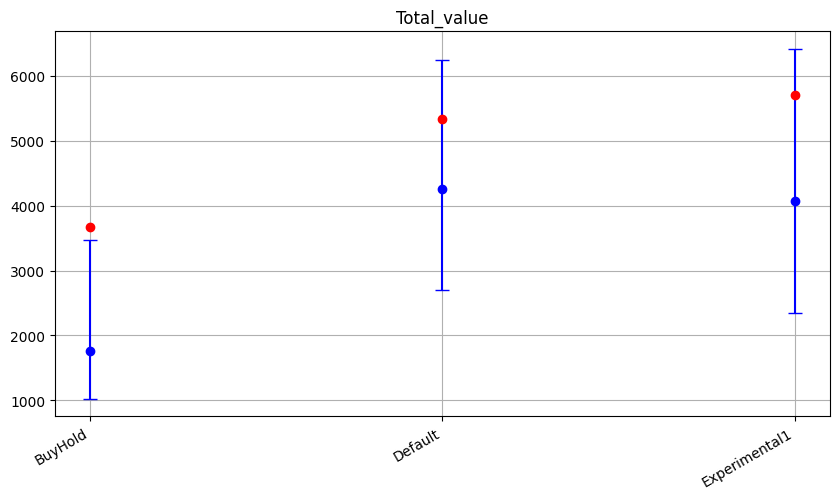

In [8]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

median = compare_res[f"{metric}_median"]
mean = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    median.index,
    median.values,
    yerr=[median - low, high - median],
    fmt="o",
    capsize=5,
    label="median",
    color="blue",
)
plt.errorbar(
    mean.index,
    mean.values,
    fmt="o",
    capsize=5,
    label="mean",
    color="red",
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()